# Credit Pre-Screening Engine - Loan Intake Optimisation
**Calibo AI Academy | Path 3 | Online Batch**
**Phase 2 - Mini Use Case 02**
**Name:** Vandana

## Problem Statement
A private bank gets about 3,000 personal loan applications every month. Every application is checked manually by an analyst and it takes about 25 minutes. Nearly half of the applications are declined, and many of them are very clear cases (very low credit score or too many EMIs already).

In this notebook I use 6 months of old decisions (12,000 applications) to build a pre-screening model. The model will auto-decline the clear declines, fast-track the clear approvals, and send the remaining applications to an analyst. The wrong decisions in each automated lane should not be more than 5%.

# CBIM Problem Canvas

| Canvas element | Answer |
|---|---|
| **Situation (S)** | The bank's retail lending unit gets about 3,000 personal loan applications every month from salaried, self-employed, business owner and gig workers. Each application is reviewed manually by an analyst and it takes about 25 minutes. |
| **Complication (C)** | Nearly half of the applications are declined and many of them are clear from the first minute (very low credit score or EMIs already taking most of the income). So analysts spend time on easy cases, applicants have to wait, and the review can be different from one analyst to another. |
| **Question (Q)** | How much of the manual review queue can a model safely take over by auto-declining clear declines and fast-tracking clear approvals, and which model and thresholds should the bank use? The bank will then decide which applications go to an analyst. |
| **SSOT** | The file `MUC02_Credit_PreScreening_Dataset.csv` (12,000 applications from April to September 2026) after the cleaning done in step 5.1. The `decision` column is the final decision of the credit team. It is not the repayment result, so the model only learns the old decisions of the analysts. |
| **Success definition** | Not more than 5% wrong decisions in the auto-decline lane and not more than 5% in the fast-track lane. After that, the model should take as many applications as possible out of the manual queue. ROC-AUC, precision and recall are used to support this, along with a fairness check by gender. |
| **Primary stakeholder** | The Credit Policy Analyst, who has to explain the model to the Head of Retail Lending. Credit analysts, applicants, and the risk and compliance team are also affected. |

## Setup
Importing the libraries and loading the settings. The CSV file should be in the same folder as this notebook.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             precision_score, recall_score, roc_auc_score)

# Chart style and colours used in the whole notebook
BLUE, RED, GREEN, GREY = "#2f6fa3", "#c44e52", "#55a868", "#bdbdbd"
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False, "axes.grid.axis": "y"})
plt.rcParams["figure.dpi"] = 100

CSV_PATH = "MUC02_Credit_PreScreening_Dataset.csv"

# Part 1 - Baseline Pre-Screener

## 5.1 Load, inspect and clean
First I check the shape, data types, null values and the overall approval rate. Then I look at the 3 problems given in the brief: missing `monthly_income`, blank `credit_score` and the very high income values. I do the cleaning on a copy (`df_clean`) so the original `df` stays the same.

In [2]:
df = pd.read_csv(CSV_PATH)
print("Shape:", df.shape)
df.head()

Shape: (12000, 19)


,application_id,application_date,age,gender,city,city_tier,employment_type,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_purpose,loan_amount,tenure_months,proposed_emi,decision
0,APP100001,2026-04-01,28,Male,Hyderabad,1,Salaried,4.1,95000.0,23500.0,784.0,109,2,0,Home Renovation,240000.0,48,6600.0,Approved
1,APP100002,2026-04-01,36,Female,Raipur,3,Business Owner,0.6,43000.0,8500.0,790.0,162,2,0,Wedding,145000.0,36,5000.0,Approved
2,APP100003,2026-04-01,35,Male,Nagpur,2,Salaried,4.4,35000.0,3500.0,718.0,151,1,1,Medical,345000.0,36,11800.0,Approved
3,APP100004,2026-04-01,42,Male,Jaipur,2,Salaried,5.8,44500.0,0.0,NaN,0,0,0,Travel,135000.0,36,4600.0,Approved
4,APP100005,2026-04-01,34,Male,Kochi,2,Self-Employed Professional,2.1,83500.0,6000.0,700.0,127,1,3,Medical,700000.0,24,33600.0,Declined


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   application_id         12000 non-null  object 
 1   application_date       12000 non-null  object 
 2   age                    12000 non-null  int64  
 3   gender                 12000 non-null  object 
 4   city                   12000 non-null  object 
 5   city_tier              12000 non-null  int64  
 6   employment_type        12000 non-null  object 
 7   years_in_current_job   12000 non-null  float64
 8   monthly_income         11559 non-null  float64
 9   existing_emi           12000 non-null  float64
 10  credit_score           10961 non-null  float64
 11  credit_history_months  12000 non-null  int64  
 12  num_active_loans       12000 non-null  int64  
 13  delinquencies_24m      12000 non-null  int64  
 14  loan_purpose           12000 non-null  object 
 15  lo

In [4]:
print("Null values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])
df.describe().round(2)

Null values per column:
monthly_income     441
credit_score      1039
dtype: int64


,age,city_tier,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_amount,tenure_months,proposed_emi
count,12000.00,12000.00,12000.00,11559.00,12000.00,10961.00,12000.00,12000.00,12000.00,12000.00,12000.00,12000.00
mean,33.15,1.71,3.77,60314.86,6273.17,725.92,114.88,1.17,0.78,379592.50,37.73,15067.10
std,7.06,0.76,3.15,48890.83,8526.17,62.56,77.33,1.15,1.23,295073.07,15.08,15160.84
min,21.00,1.00,0.00,12000.00,0.00,479.00,0.00,0.00,0.00,50000.00,12.00,1200.00
25%,28.00,1.00,1.50,33500.00,0.00,684.00,54.00,0.00,0.00,175000.00,24.00,6000.00
50%,33.00,2.00,3.00,50500.00,4000.00,726.00,114.00,1.00,0.00,300000.00,36.00,10600.00
75%,38.00,2.00,5.10,74750.00,8500.00,769.00,169.00,2.00,1.00,490000.00,48.00,18700.00
max,60.00,3.00,30.00,1656000.00,96500.00,890.00,395.00,8.00,11.00,2500000.00,60.00,224500.00


In [5]:
# Overall approval rate - how balanced is the target?
print(df["decision"].value_counts())
print()
print((df["decision"].value_counts(normalize=True) * 100).round(2))
print("\nOverall approval rate:", round((df["decision"] == "Approved").mean() * 100, 2), "%")

decision
Approved    6353
Declined    5647
Name: count, dtype: int64

decision
Approved    52.94
Declined    47.06
Name: proportion, dtype: float64

Overall approval rate: 52.94 %


In [6]:
# Issue 1 - missing monthly_income: which employment types?
miss_inc = df.groupby("employment_type")["monthly_income"].apply(lambda s: s.isnull().sum())
miss_inc_pct = df.groupby("employment_type")["monthly_income"].apply(lambda s: s.isnull().mean() * 100)
print(pd.DataFrame({"missing_count": miss_inc, "missing_%": miss_inc_pct.round(2)}))

                            missing_count  missing_%
employment_type                                     
Business Owner                        227      12.98
Gig / Contract                         11       0.62
Salaried                               49       0.69
Self-Employed Professional            154      10.78


In [7]:
# Issue 2 - blank credit_score: what does credit_history_months say?
no_score = df[df["credit_score"].isnull()]
print("Applicants with a blank credit score:", len(no_score))
print("\ncredit_history_months for those rows:")
print(no_score["credit_history_months"].value_counts())
print("\nShare of all applications:", round(len(no_score) / len(df) * 100, 2), "%")

Applicants with a blank credit score: 1039

credit_history_months for those rows:
credit_history_months
0    1039
Name: count, dtype: int64

Share of all applications: 8.66 %


In [8]:
# Issue 3 - implausible monthly_income values
print("Maximum monthly_income:", df["monthly_income"].max())
print("99th percentile        :", df["monthly_income"].quantile(0.99))
outliers = df[df["monthly_income"] > 400000]
print("\nRows above 4,00,000 per month:", len(outliers))
print(outliers["employment_type"].value_counts())
outliers[["application_id", "employment_type", "monthly_income"]].sort_values("monthly_income", ascending=False).head(10)

Maximum monthly_income: 1656000.0
99th percentile        : 191000.0

Rows above 4,00,000 per month: 17
employment_type
Salaried    17
Name: count, dtype: int64


,application_id,employment_type,monthly_income
1467,APP101468,Salaried,1656000.0
300,APP100301,Salaried,1254000.0
2493,APP102494,Salaried,1212000.0
589,APP100590,Salaried,1068000.0
9849,APP109850,Salaried,990000.0
1848,APP101849,Salaried,984000.0
2488,APP102489,Salaried,972000.0
4010,APP104011,Salaried,900000.0
4898,APP104899,Salaried,870000.0
9261,APP109262,Salaried,702000.0


In [9]:
# Check my idea: annual salary entered in the monthly column.
# After dividing by 12 these should come in the normal Salaried range.
fixed = outliers["monthly_income"] / 12
print("After dividing by 12 -> min:", round(fixed.min()), " max:", round(fixed.max()))
print("Normal Salaried range -> median:", df.loc[(df["employment_type"] == "Salaried") & (df["monthly_income"] <= 400000), "monthly_income"].median())

After dividing by 12 -> min: 33500  max: 138000
Normal Salaried range -> median: 50000.0


In [10]:
# ---- Cleaning (on a copy - the raw data stays untouched) ----
df_clean = df.copy()

# 1) Annual income typed into the monthly field -> divide by 12
INCOME_CAP = 400000
mask_annual = df_clean["monthly_income"] > INCOME_CAP
df_clean.loc[mask_annual, "monthly_income"] = df_clean.loc[mask_annual, "monthly_income"] / 12

# 2) Missing income -> median income of the same employment type
income_medians = df_clean.groupby("employment_type")["monthly_income"].median()
df_clean["monthly_income"] = df_clean["monthly_income"].fillna(
    df_clean["employment_type"].map(income_medians)
)

# 3) Blank credit_score is kept as-is (new-to-credit). It is flagged in Step 5.3 and imputed later inside the model.

print("Median income used for filling:")
print(income_medians.round(0))
print("\nMissing monthly_income after cleaning:", df_clean["monthly_income"].isnull().sum())
print("Max monthly_income after cleaning:", round(df_clean["monthly_income"].max()))
print("Rows kept:", len(df_clean), "of", len(df))

Median income used for filling:
employment_type
Business Owner                69500.0
Gig / Contract                28000.0
Salaried                      50000.0
Self-Employed Professional    75000.0
Name: monthly_income, dtype: float64

Missing monthly_income after cleaning: 0
Max monthly_income after cleaning: 396000
Rows kept: 12000 of 12000


### 5.1 What I found and the cleaning decisions
The dataset has 12,000 rows and 19 columns. Only two columns have null values: `monthly_income` (441 missing) and `credit_score` (1,039 missing). The overall approval rate is **52.94%** and the decline rate is 47.06%, so the target is fairly balanced.

| # | Problem | What I found | What I did | Why |
|---|---|---|---|---|
| 1 | Missing `monthly_income` | 441 rows. Most of them are Business Owner (227 rows, 13.0% of the group) and Self-Employed Professional (154 rows, 10.8%). Salaried and Gig are below 1%. | Filled with the median income of the same employment type (Business Owner 69,500, Self-Employed 75,000, Salaried 50,000, Gig 28,000). | Income is missing mostly for self-employed people, so one common median would not be correct. I used median because income has some very high values. Dropping the rows would remove about 4% of the data. |
| 2 | Blank `credit_score` | 1,039 rows (8.7%). All of them have `credit_history_months = 0`. | Kept all the rows and made a flag `is_ntc = 1` in step 5.3. | These are not errors. They are new-to-credit applicants who have no credit history. If I drop them, the model will not learn about this group. |
| 3 | Very high `monthly_income` | Maximum is 1,656,000 per month. There are 17 rows above 4,00,000 and all of them are Salaried. After dividing by 12 they become 33,500 to 1,38,000, which is a normal salary range. | Divided these 17 values by 12. | Most likely the annual salary was entered in the monthly column. Dividing by 12 fixes it and I do not lose any applicant. |

Note: I calculated the median incomes on the full data. It is a small shortcut and in real use it should be calculated only on the training data.

## 5.2 What drives approval today?
Before building the model I want to see what the credit team is actually doing. I grouped the credit score into bands (and a separate "No score" group) and checked the approval rate. I also checked the approval rate by employment type.

            applications  approval_rate_%
score_band                               
Below 600            246             2.03
600-649              933             3.22
650-699             2529            32.50
700-749             3377            54.37
750-799             2526            77.20
800+                1350            85.19
No score            1039            53.90


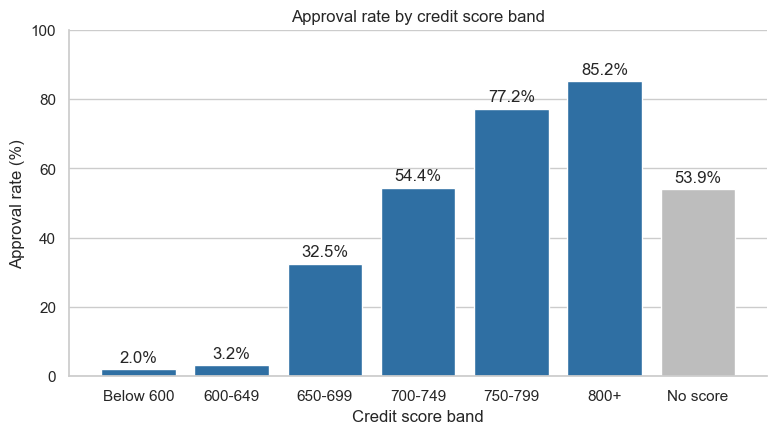

In [11]:
score_bins = [0, 599, 649, 699, 749, 799, np.inf]
score_labels = ["Below 600", "600-649", "650-699", "700-749", "750-799", "800+"]

df_clean["score_band"] = pd.cut(df_clean["credit_score"], bins=score_bins, labels=score_labels).astype("object")
df_clean["score_band"] = df_clean["score_band"].fillna("No score")
df_clean["approved_flag"] = (df_clean["decision"] == "Approved").astype(int)

band_order = score_labels + ["No score"]
approval_by_score = df_clean.groupby("score_band")["approved_flag"].mean().mul(100).reindex(band_order)
band_size = df_clean["score_band"].value_counts().reindex(band_order)
print(pd.DataFrame({"applications": band_size, "approval_rate_%": approval_by_score.round(2)}))

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = [BLUE] * 6 + [GREY]
bars = ax.bar(band_order, approval_by_score.values, color=colors)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_title("Approval rate by credit score band")
ax.set_xlabel("Credit score band")
ax.set_ylabel("Approval rate (%)")
ax.set_ylim(0, 100)
plt.show()

employment_type
Salaried                      58.37
Business Owner                51.17
Self-Employed Professional    50.56
Gig / Contract                34.94
Name: approved_flag, dtype: float64


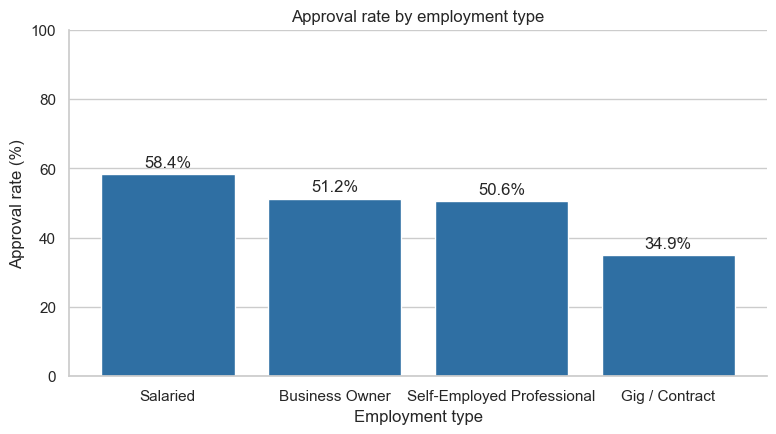

In [12]:
approval_by_emp = df_clean.groupby("employment_type")["approved_flag"].mean().mul(100).sort_values(ascending=False)
print(approval_by_emp.round(2))

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(approval_by_emp.index, approval_by_emp.values, color=BLUE)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_title("Approval rate by employment type")
ax.set_xlabel("Employment type")
ax.set_ylabel("Approval rate (%)")
ax.set_ylim(0, 100)
plt.show()

In [13]:
scored = df_clean["credit_score"].notnull()
print("Approval rate - applicants WITH a score   :", round(df_clean.loc[scored, "approved_flag"].mean() * 100, 2), "%")
print("Approval rate - applicants with NO score  :", round(df_clean.loc[~scored, "approved_flag"].mean() * 100, 2), "%")
print("Approval rate - score below 650           :", round(df_clean.loc[df_clean["credit_score"] < 650, "approved_flag"].mean() * 100, 2), "%")
print("Approval rate - score 650 and above       :", round(df_clean.loc[df_clean["credit_score"] >= 650, "approved_flag"].mean() * 100, 2), "%")

Approval rate - applicants WITH a score   : 52.85 %
Approval rate - applicants with NO score  : 53.9 %
Approval rate - score below 650           : 2.97 %
Approval rate - score 650 and above       : 58.86 %


### 5.2 Findings
**Is there a score below which applications are almost never approved?** Yes. The approval rate is only **2.0%** for scores below 600 and **3.2%** for 600-649. At 650-699 it jumps to **32.5%** and then goes up to 54.4%, 77.2% and 85.2% for the higher bands. So the bank has an unwritten rule that a credit score below about 650 is not approved.

**Applicants with no score:** Their approval rate is **53.9%** and for applicants with a score it is **52.9%**. These are almost the same, so the credit team does not treat "no score" as a bad score.

**Employment type:** Salaried has the highest approval rate (58.4%), Business Owner and Self-Employed Professional are around 51% (51.2% and 50.6%), and Gig / Contract is much lower (34.9%). I will keep this in mind for the fairness check.

## 5.3 Engineer the affordability features
I created three new columns:
- `foir` = (existing EMI + proposed EMI) / monthly income
- `loan_to_income` = loan amount / (monthly income x 12)
- `is_ntc` = 1 if the applicant has no credit score, else 0

Then I grouped FOIR into bands (below 30%, 30-40%, 40-50%, 50-55%, above 55%) and plotted the approval rate for each band.

In [14]:
df_clean["foir"] = (df_clean["existing_emi"] + df_clean["proposed_emi"]) / df_clean["monthly_income"]
df_clean["loan_to_income"] = df_clean["loan_amount"] / (df_clean["monthly_income"] * 12)
df_clean["is_ntc"] = df_clean["credit_score"].isnull().astype(int)

print("New-to-credit applicants:", df_clean["is_ntc"].sum(), f"({df_clean['is_ntc'].mean():.1%})")
df_clean[["foir", "loan_to_income", "is_ntc"]].describe().round(3)

New-to-credit applicants: 1039 (8.7%)


,foir,loan_to_income,is_ntc
count,12000.000,12000.000,12000.000
mean,0.358,0.531,0.087
std,0.207,0.225,0.281
min,0.005,0.015,0.000
25%,0.215,0.347,0.000
50%,0.317,0.519,0.000
75%,0.450,0.699,0.000
max,3.393,2.778,1.000


           applications  approval_rate
foir_band                             
Below 30%          5488          65.49
30-40%             2499          58.98
40-50%             1767          47.82
50-55%              531          32.39
Above 55%          1715          15.63


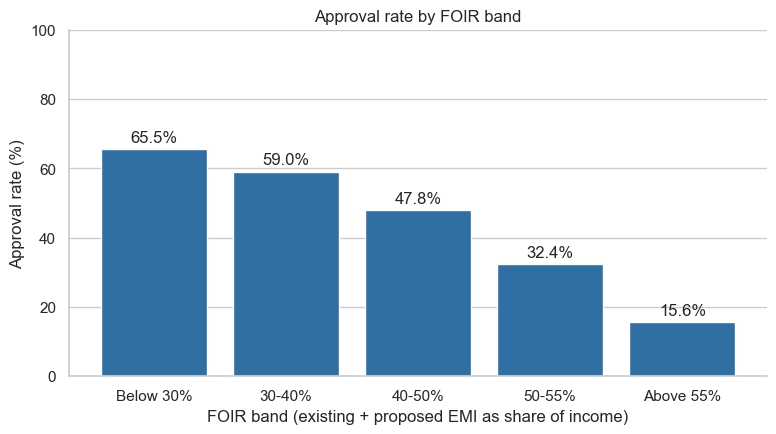

In [15]:
foir_bins = [-np.inf, 0.30, 0.40, 0.50, 0.55, np.inf]
foir_labels = ["Below 30%", "30-40%", "40-50%", "50-55%", "Above 55%"]
df_clean["foir_band"] = pd.cut(df_clean["foir"], bins=foir_bins, labels=foir_labels, right=False)

foir_tbl = df_clean.groupby("foir_band", observed=True).agg(
    applications=("approved_flag", "size"),
    approval_rate=("approved_flag", "mean"))
foir_tbl["approval_rate"] = (foir_tbl["approval_rate"] * 100).round(2)
print(foir_tbl)

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(foir_tbl.index.astype(str), foir_tbl["approval_rate"], color=BLUE)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_title("Approval rate by FOIR band")
ax.set_xlabel("FOIR band (existing + proposed EMI as share of income)")
ax.set_ylabel("Approval rate (%)")
ax.set_ylim(0, 100)
plt.show()

### 5.3 Findings
The approval rate goes down as FOIR goes up: 65.5% (below 30%), 59.0% (30-40%), 47.8% (40-50%), 32.4% (50-55%) and only 15.6% (above 55%). The fall is bigger after 40%: it drops by about 11 points from the 30-40% band to the 40-50% band, and then by 15 and 17 points in the next two bands.

If I write a credit policy, I will propose a **FOIR limit of 50%**, and applications between 40% and 50% can be checked by an analyst. I would not make it a strict rule because some applicants above 50% are still approved.

## 5.4 Build the logistic regression pre-screener
The target is 1 if the application is Declined and 0 if Approved, so the model predicts declines. I used the 12 features given in the brief and did not use `application_id`, `application_date`, `city`, `gender` and `decision`. The blank credit scores are filled with the median (the `is_ntc` flag shows which ones were filled). `employment_type` and `loan_purpose` are one-hot encoded and the numeric features are scaled. The data is split 80/20 with `stratify=y` and `random_state=42`. The median and the scaler are learned only from the training data.

In [16]:
numeric_features = ["credit_score", "is_ntc", "foir", "loan_to_income", "delinquencies_24m",
                    "num_active_loans", "years_in_current_job", "age", "tenure_months", "city_tier"]
categorical_features = ["employment_type", "loan_purpose"]
feature_columns = numeric_features + categorical_features

X = df_clean[feature_columns].copy()
y = (df_clean["decision"] == "Declined").astype(int)      # 1 = Declined, 0 = Approved

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Decline rate - train:", round(y_train.mean(), 4), " test:", round(y_test.mean(), 4))

Train: (9600, 12)  Test: (2400, 12)
Decline rate - train: 0.4706  test: 0.4704


In [17]:
# Step by step version (I build the same thing as one Pipeline in step 5.8)
train_median_score = X_train["credit_score"].median()
print("Median credit score (training rows):", train_median_score)

def prepare_manual(frame):
    f = frame.copy()
    f["credit_score"] = f["credit_score"].fillna(train_median_score)      # is_ntc keeps the "was blank" information
    f = pd.get_dummies(f, columns=categorical_features, dtype=float)
    return f

Xtr = prepare_manual(X_train)
Xte = prepare_manual(X_test).reindex(columns=Xtr.columns, fill_value=0.0)

scaler_manual = StandardScaler().fit(Xtr[numeric_features])               # fitted on training rows only
Xtr_s, Xte_s = Xtr.copy(), Xte.copy()
Xtr_s[numeric_features] = scaler_manual.transform(Xtr[numeric_features])
Xte_s[numeric_features] = scaler_manual.transform(Xte[numeric_features])

lr_manual = LogisticRegression(max_iter=1000).fit(Xtr_s, y_train)
pred_manual = lr_manual.predict(Xte_s)
proba_manual = lr_manual.predict_proba(Xte_s)[:, 1]
print("Logistic Regression trained on", Xtr_s.shape[1], "model columns.")

Median credit score (training rows): 726.0
Logistic Regression trained on 21 model columns.


Accuracy                : 79.08%
Precision (Declined)    : 79.11%
Recall    (Declined)    : 75.47%

                  Predicted Approved  Predicted Declined
Actual Approved                1046                 225
Actual Declined                 277                 852


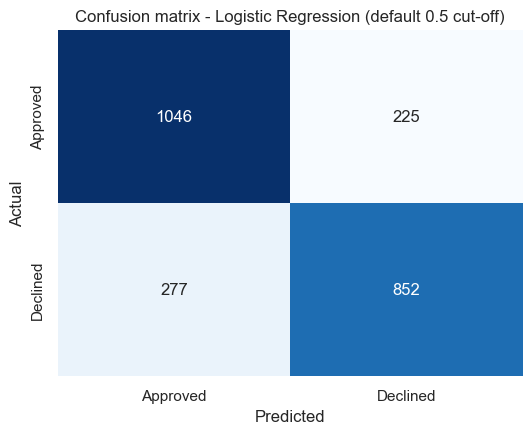

In [18]:
acc = accuracy_score(y_test, pred_manual)
cm = confusion_matrix(y_test, pred_manual, labels=[0, 1])
prec = precision_score(y_test, pred_manual)
rec = recall_score(y_test, pred_manual)

print(f"Accuracy                : {acc:.2%}")
print(f"Precision (Declined)    : {prec:.2%}")
print(f"Recall    (Declined)    : {rec:.2%}")
print("\n", pd.DataFrame(cm, index=["Actual Approved", "Actual Declined"],
                          columns=["Predicted Approved", "Predicted Declined"]))

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Approved", "Declined"], yticklabels=["Approved", "Declined"])
ax.set_title("Confusion matrix - Logistic Regression (default 0.5 cut-off)")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
plt.show()

                       feature  coefficient        direction
                          foir     1.221619  towards DECLINE
                  credit_score    -1.009297 towards APPROVAL
             delinquencies_24m     0.978398  towards DECLINE
employment_type_Gig / Contract     0.619425  towards DECLINE
      employment_type_Salaried    -0.445238 towards APPROVAL


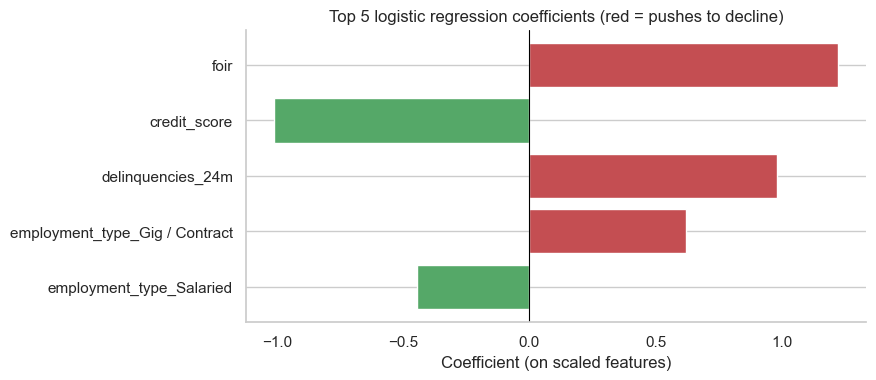

In [19]:
coef = pd.DataFrame({"feature": Xtr_s.columns, "coefficient": lr_manual.coef_[0]})
coef["direction"] = np.where(coef["coefficient"] > 0, "towards DECLINE", "towards APPROVAL")
top5 = coef.reindex(coef["coefficient"].abs().sort_values(ascending=False).index).head(5)
print(top5.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.8))
t = top5.iloc[::-1]
ax.barh(t["feature"], t["coefficient"], color=[RED if c > 0 else GREEN for c in t["coefficient"]])
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Top 5 logistic regression coefficients (red = pushes to decline)")
ax.set_xlabel("Coefficient (on scaled features)")
plt.show()

### 5.4 Findings
On the 2,400 test applications the model has **accuracy 79.08%**, **precision 79.11%** and **recall 75.47%** for the Declined class.

| | Predicted Approved | Predicted Declined |
|---|---:|---:|
| **Actual Approved** | 1,046 | 225 |
| **Actual Declined** | 277 | 852 |

**Confusion matrix in business language:**
- **225 creditworthy applicants** (approved by the credit team) would be wrongly declined. This is 17.7% of all approved applications, which is too high for an automatic decline. That is why I use a higher threshold in step 5.5.
- 277 applications that were declined by the team are predicted as approved. In a pre-screener these will just go to an analyst, so this mistake is less costly.
- When the model says "decline" it is correct 79% of the time, and it finds 75% of all the real declines.

**Top 5 coefficients (for a credit analyst):**
- **foir (+1.22):** this is the biggest factor. When FOIR is higher, the chance of decline goes up a lot (odds become about 3.4 times for one standard deviation).
- **credit_score (-1.01):** a higher credit score pushes the application towards approval.
- **delinquencies_24m (+0.98):** every extra late or missed payment pushes the application towards decline.
- **Gig / Contract (+0.62):** gig workers are declined more even when the score and FOIR are the same.
- **Salaried (-0.45):** salaried applicants are more likely to be approved.

This matches what I saw in steps 5.2 and 5.3, so the model is learning the real credit policy and not noise.

## 5.5 Set the auto-decline threshold
If I use the default 0.5 cut-off, many good customers will be declined. So the bank should auto-decline only when the model is very sure. I used `predict_proba` on the test set and made a table for each threshold. It shows the percentage of applications that are auto-declined and, out of those, the percentage that the credit team had actually approved (wrongly declined). The bank allows a maximum of 5% wrong declines.

In [20]:
y_arr = y_test.to_numpy()
thresholds = [0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95]

rows = []
for t in thresholds:
    auto = proba_manual >= t
    n = int(auto.sum())
    wrong = int(((y_arr == 0) & auto).sum())          # auto-declined but the credit team had approved
    rows.append({"Threshold": t,
                 "Auto-declined": n,
                 "Auto-decline rate (%)": n / len(y_arr) * 100,
                 "Wrongly declined": wrong,
                 "Wrong-decline rate (%)": wrong / n * 100 if n else np.nan})
thr_table = pd.DataFrame(rows)
thr_table.round(2)

,Threshold,Auto-declined,Auto-decline rate (%),Wrongly declined,Wrong-decline rate (%)
0,0.50,1077,44.88,225,20.89
1,0.60,902,37.58,152,16.85
2,0.70,738,30.75,89,12.06
3,0.80,563,23.46,40,7.10
4,0.85,472,19.67,28,5.93
5,0.90,365,15.21,17,4.66
6,0.95,239,9.96,5,2.09


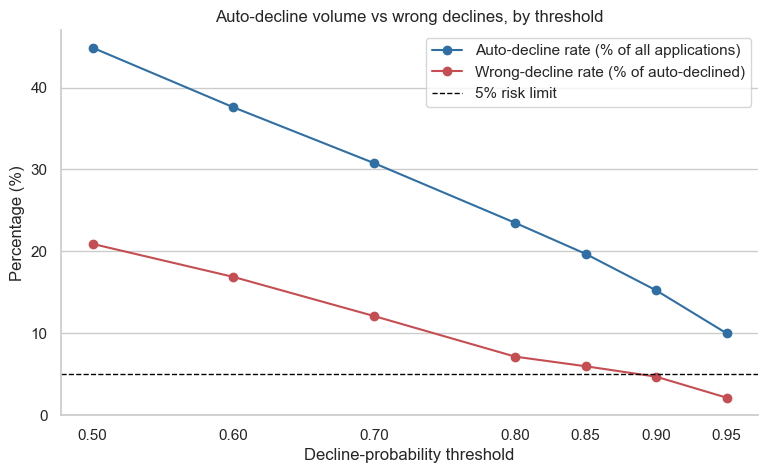

In [21]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(thr_table["Threshold"], thr_table["Auto-decline rate (%)"], marker="o", color=BLUE, label="Auto-decline rate (% of all applications)")
ax.plot(thr_table["Threshold"], thr_table["Wrong-decline rate (%)"], marker="o", color=RED, label="Wrong-decline rate (% of auto-declined)")
ax.axhline(5, ls="--", color="black", lw=1, label="5% risk limit")
ax.set_xticks(thresholds)
ax.set_title("Auto-decline volume vs wrong declines, by threshold")
ax.set_xlabel("Decline-probability threshold")
ax.set_ylabel("Percentage (%)")
ax.legend()
plt.show()

In [22]:
ok = thr_table[thr_table["Wrong-decline rate (%)"] <= 5]
best = ok.loc[ok["Auto-decline rate (%)"].idxmax()]
BASE_THRESHOLD = float(best["Threshold"])

print("Chosen threshold      :", BASE_THRESHOLD)
print("Auto-decline rate     :", round(best["Auto-decline rate (%)"], 2), "%")
print("Wrong-decline rate    :", round(best["Wrong-decline rate (%)"], 2), "%")

MONTHLY_APPS, MIN_PER_REVIEW = 3000, 25
base_monthly_apps = MONTHLY_APPS * best["Auto-decline rate (%)"] / 100
base_monthly_hours = base_monthly_apps * MIN_PER_REVIEW / 60
print(f"\nPer month ({MONTHLY_APPS} applications, {MIN_PER_REVIEW} min each):")
print(f"  Applications auto-declined : {base_monthly_apps:.0f}")
print(f"  Analyst hours freed        : {base_monthly_hours:.1f}")

Chosen threshold      : 0.9
Auto-decline rate     : 15.21 %
Wrong-decline rate    : 4.66 %

Per month (3000 applications, 25 min each):
  Applications auto-declined : 456
  Analyst hours freed        : 190.1


### 5.5 Findings
| Threshold | Auto-declined | % of all applications | Wrongly declined | Wrong-decline rate |
|---:|---:|---:|---:|---:|
| 0.5 | 1077 | 44.88% | 225 | 20.89% |
| 0.6 | 902 | 37.58% | 152 | 16.85% |
| 0.7 | 738 | 30.75% | 89 | 12.06% |
| 0.8 | 563 | 23.46% | 40 | 7.10% |
| 0.85 | 472 | 19.67% | 28 | 5.93% |
| 0.9 | 365 | 15.21% | 17 | 4.66% |
| 0.95 | 239 | 9.96% | 5 | 2.09% |

At 0.85 the wrong-decline rate is 5.93%, which is more than 5%. At **0.9** it is 4.66%, so this is the lowest threshold that follows the 5% rule and it auto-declines the most applications. So I choose **threshold 0.9**. It auto-declines 15.21% of applications (365 in the test set) and 17 of them were wrongly declined.

**Monthly business case:** with 3,000 applications per month and 25 minutes per review, about **456 applications** will not need a manual review. This saves about **190 analyst hours per month**.

## 5.6 Fairness check
I did not use gender as a feature, but that alone does not make the model fair. So I checked three things: the historical approval rate by gender (overall and for each employment type), the median income and gig worker share by gender, and the auto-decline rate by gender from my model at the chosen threshold.

In [23]:
# (a) Historical approval rate by gender - overall and within employment type
overall_g = df_clean.groupby("gender")["approved_flag"].agg(applications="size", approval_rate="mean")
overall_g["approval_rate"] = (overall_g["approval_rate"] * 100).round(2)
print(overall_g, "\n")

by_emp_g = (df_clean.pivot_table(index="employment_type", columns="gender", values="approved_flag", aggfunc="mean") * 100).round(2)
by_emp_g["gap (M - F)"] = (by_emp_g["Male"] - by_emp_g["Female"]).round(2)
by_emp_g

        applications  approval_rate
gender                             
Female          3795          50.43
Male            8205          54.10 



gender,Female,Male,gap (M - F)
employment_type,,,
Business Owner,51.62,51.05,-0.57
Gig / Contract,34.65,35.18,0.53
Salaried,56.79,59.06,2.27
Self-Employed Professional,47.63,51.97,4.34


In [24]:
# (b) Income and employment mix by gender
profile = df_clean.groupby("gender").agg(
    median_monthly_income=("monthly_income", "median"),
    gig_contract_share=("employment_type", lambda s: (s == "Gig / Contract").mean() * 100))
profile["gig_contract_share"] = profile["gig_contract_share"].round(2)
print(profile, "\n")

mix = (pd.crosstab(df_clean["gender"], df_clean["employment_type"], normalize="index") * 100).round(1)
mix

        median_monthly_income  gig_contract_share
gender                                           
Female                45000.0               21.37
Male                  55000.0               11.64 



employment_type,Business Owner,Gig / Contract,Salaried,Self-Employed Professional
gender,,,,
Female,9.7,21.4,56.7,12.2
Male,16.8,11.6,59.8,11.7


In [25]:
# (c) What does the model do at the Step 5.5 threshold? (test set only)
fair = pd.DataFrame({
    "gender": df_clean.loc[X_test.index, "gender"].to_numpy(),
    "actual_declined": y_arr,
    "auto_declined": (proba_manual >= BASE_THRESHOLD).astype(int)})

fair_tbl = fair.groupby("gender").agg(
    test_applications=("actual_declined", "size"),
    historical_decline_rate=("actual_declined", "mean"),
    auto_decline_rate=("auto_declined", "mean"),
    auto_declined_count=("auto_declined", "sum"))

wrong = fair[fair["auto_declined"] == 1].groupby("gender")["actual_declined"].apply(lambda s: (s == 0).mean())
fair_tbl["wrong_decline_rate_of_auto_declined"] = wrong
for c in ["historical_decline_rate", "auto_decline_rate", "wrong_decline_rate_of_auto_declined"]:
    fair_tbl[c] = (fair_tbl[c] * 100).round(2)
fair_tbl

,test_applications,historical_decline_rate,auto_decline_rate,auto_declined_count,wrong_decline_rate_of_auto_declined
gender,,,,,
Female,750,49.73,15.60,117,3.42
Male,1650,45.82,15.03,248,5.24


### 5.6 Findings
**Is there a gap in the historical data?** Yes. Men were approved 54.10% of the time and women 50.43%, so the gap is 3.67 points.

**What explains it?** Women have a lower median income (45,000 vs 55,000) and more of them are Gig / Contract workers (21.4% vs 11.6%), and gig workers have the lowest approval rate. But this is not the full reason, because the gap is still there inside Salaried (2.3 points) and Self-Employed Professional (4.3 points).

**Does the model widen the gap?** At threshold 0.9 the model auto-declines 15.60% of women and 15.03% of men, so the difference is only 0.57 points. In the same test data the historical decline rates differ by 3.9 points. So the model does not widen the gap, it is a little smaller. The number of women in the test set is small (750), so this is only an indication.

**Should gender be used?** No, gender should never be used as a feature in a credit model. But leaving it out does not fully solve the problem, because income and employment type can work as a substitute for gender, and the model learns from old decisions which already have a gap. So the bank should keep checking the results by gender after the launch.

## 5.7 Interim Briefing
For the logistic regression model I recommend an auto-decline threshold of **0.90**. At this threshold 15.2% of applications are auto-declined and only 4.66% of them were approved by the credit team, which is inside the 5% limit. With 3,000 applications a month, this frees about 456 applications and 190 analyst hours per month. The weakness I want Part 2 to fix is that this model only removes the clear declines (about 1 in 7 applications), so I want to check if a better model and a second fast-track lane can take over more applications and still keep the 5% limit.

# Part 2 - Model Comparison & Two-Lane Design

## 5.8 Rebuild the baseline as a pipeline
I rebuilt the step 5.4 model as one scikit-learn `Pipeline`. A `ColumnTransformer` imputes and scales the numeric features and one-hot encodes the categorical features, and then `LogisticRegression` is applied. I fitted it on the same training split. I also made a function `engineer_features()` which does the cleaning and the new features (foir, loan_to_income, is_ntc) on raw rows, so I can pass the raw CSV rows directly to the pipeline.

In [26]:
def engineer_features(raw):
    """Takes raw rows from the CSV and gives the features for the model.
    Uses the same cleaning and feature steps as 5.1 and 5.3."""
    f = raw.copy()
    annual = f["monthly_income"] > INCOME_CAP                              # annual figure typed as monthly
    f.loc[annual, "monthly_income"] = f.loc[annual, "monthly_income"] / 12
    f["monthly_income"] = f["monthly_income"].fillna(f["employment_type"].map(income_medians))
    f["foir"] = (f["existing_emi"] + f["proposed_emi"]) / f["monthly_income"]
    f["loan_to_income"] = f["loan_amount"] / (f["monthly_income"] * 12)
    f["is_ntc"] = f["credit_score"].isnull().astype(int)
    return f[feature_columns]

# Check: the function on all raw rows should give the same X as before
raw_all = pd.read_csv(CSV_PATH)
print("Function reproduces training features exactly:", np.allclose(
    engineer_features(raw_all).select_dtypes("number").to_numpy(dtype=float),
    X.select_dtypes("number").to_numpy(dtype=float), equal_nan=True))

Function reproduces training features exactly: True


In [27]:
numeric_transformer = Pipeline([("imputer", SimpleImputer(strategy="median")),
                                ("scaler", StandardScaler())])
categorical_transformer = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                    ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([("num", numeric_transformer, numeric_features),
                                  ("cat", categorical_transformer, categorical_features)])

baseline_pipeline = Pipeline([("preprocessor", preprocessor),
                              ("classifier", LogisticRegression(max_iter=1000))])
baseline_pipeline.fit(X_train, y_train)        # same training split as Step 5.4

pred_pipe = baseline_pipeline.predict(X_test)
proba_pipe = baseline_pipeline.predict_proba(X_test)[:, 1]

print(f"Pipeline accuracy      : {accuracy_score(y_test, pred_pipe):.2%}   (Step 5.4: {acc:.2%})")
print("Pipeline confusion matrix:\n", confusion_matrix(y_test, pred_pipe, labels=[0, 1]))
print("Identical predictions to Step 5.4 :", bool((pred_pipe == pred_manual).all()))
print("Max difference in probabilities   :", float(np.abs(proba_pipe - proba_manual).max()))

Pipeline accuracy      : 79.08%   (Step 5.4: 79.08%)
Pipeline confusion matrix:
 [[1046  225]
 [ 277  852]]
Identical predictions to Step 5.4 : True
Max difference in probabilities   : 2.220446049250313e-16


In [28]:
# Five most recent applications, as RAW rows straight from the CSV
raw = pd.read_csv(CSV_PATH)
latest_five = raw.sort_values(["application_date", "application_id"], ascending=False).head(5)

scores = baseline_pipeline.predict_proba(engineer_features(latest_five))[:, 1]
out = latest_five[["application_id", "application_date", "employment_type", "credit_score", "decision"]].copy()
out["decline_probability"] = scores.round(4)
out.reset_index(drop=True)

,application_id,application_date,employment_type,credit_score,decision,decline_probability
0,APP112000,2026-09-30,Salaried,655.0,Approved,0.4041
1,APP111999,2026-09-30,Salaried,685.0,Approved,0.2473
2,APP111998,2026-09-30,Salaried,666.0,Approved,0.5702
3,APP111997,2026-09-30,Salaried,743.0,Declined,0.8471
4,APP111996,2026-09-30,Salaried,684.0,Declined,0.5259


### 5.8 Findings
The pipeline gives the same result as step 5.4: accuracy 79.08%, the same confusion matrix and the same predictions. For the 5 most recent applications (all dated 30 September 2026) the decline probabilities are **0.404, 0.247, 0.570, 0.847, 0.526**. None of them is above 0.9, so none would be auto-declined.

**Why package the model like this?** In a pipeline, the imputer, scaler and encoder are learned only from the training data and then used in the same way on new data. This avoids data leakage, which means information from the test data or future data going into the training steps and making the results look better than they are. It also makes sure that next month's applications are processed in exactly the same way as the training data.

## 5.9 Compare models with cross-validation
I put four models in the same pipeline: Logistic Regression, Decision Tree, Random Forest and Gradient Boosting. I used 5-fold StratifiedKFold cross-validation on the **training set only** and noted the mean ROC-AUC, accuracy, precision and recall for the Declined class. After choosing one model, I tested it only once on the test set.

In [29]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced", n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}
model_pipes = {name: Pipeline([("preprocessor", clone(preprocessor)), ("classifier", clf)])
               for name, clf in models.items()}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"roc_auc": "roc_auc", "accuracy": "accuracy", "precision": "precision", "recall": "recall"}

rows = []
for name, pipe in model_pipes.items():
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)   # training set ONLY
    rows.append({"Model": name,
                 "Mean ROC-AUC": s["test_roc_auc"].mean(),
                 "Mean Accuracy": s["test_accuracy"].mean(),
                 "Mean Precision (Declined)": s["test_precision"].mean(),
                 "Mean Recall (Declined)": s["test_recall"].mean()})
cv_table = pd.DataFrame(rows).sort_values("Mean ROC-AUC", ascending=False).reset_index(drop=True)
cv_table.round(4)

,Model,Mean ROC-AUC,Mean Accuracy,Mean Precision (Declined),Mean Recall (Declined)
0,Gradient Boosting,0.8889,0.7999,0.8117,0.7488
1,Random Forest,0.8800,0.7923,0.7930,0.7563
2,Logistic Regression,0.8679,0.7751,0.7803,0.7271
3,Decision Tree,0.7190,0.7200,0.7026,0.7027


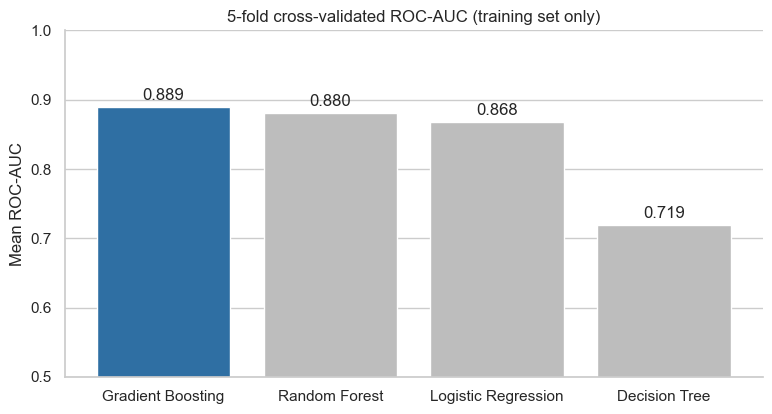

In [30]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(cv_table["Model"], cv_table["Mean ROC-AUC"], color=[BLUE if i == 0 else GREY for i in range(len(cv_table))])
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set_ylim(0.5, 1.0)
ax.set_title("5-fold cross-validated ROC-AUC (training set only)")
ax.set_ylabel("Mean ROC-AUC")
plt.show()

In [31]:
# Choose one model, then touch the test set once
chosen_name = cv_table.loc[0, "Model"]
chosen_pipe = clone(model_pipes[chosen_name]).fit(X_train, y_train)

pred_c = chosen_pipe.predict(X_test)
proba_c = chosen_pipe.predict_proba(X_test)[:, 1]
print("Chosen model:", chosen_name)
print(f"Test ROC-AUC   : {roc_auc_score(y_test, proba_c):.4f}")
print(f"Test accuracy  : {accuracy_score(y_test, pred_c):.4f}")
print(f"Test precision : {precision_score(y_test, pred_c):.4f}   (Declined)")
print(f"Test recall    : {recall_score(y_test, pred_c):.4f}   (Declined)")
print(f"\nFor reference - Logistic Regression test ROC-AUC: {roc_auc_score(y_test, proba_pipe):.4f}")

Chosen model: Gradient Boosting
Test ROC-AUC   : 0.8854
Test accuracy  : 0.8029
Test precision : 0.8148   (Declined)
Test recall    : 0.7520   (Declined)

For reference - Logistic Regression test ROC-AUC: 0.8674


                       feature  importance
             delinquencies_24m      0.3078
                  credit_score      0.2879
                          foir      0.2845
          years_in_current_job      0.0288
                        is_ntc      0.0223
employment_type_Gig / Contract      0.0183
                loan_to_income      0.0149
      employment_type_Salaried      0.0147


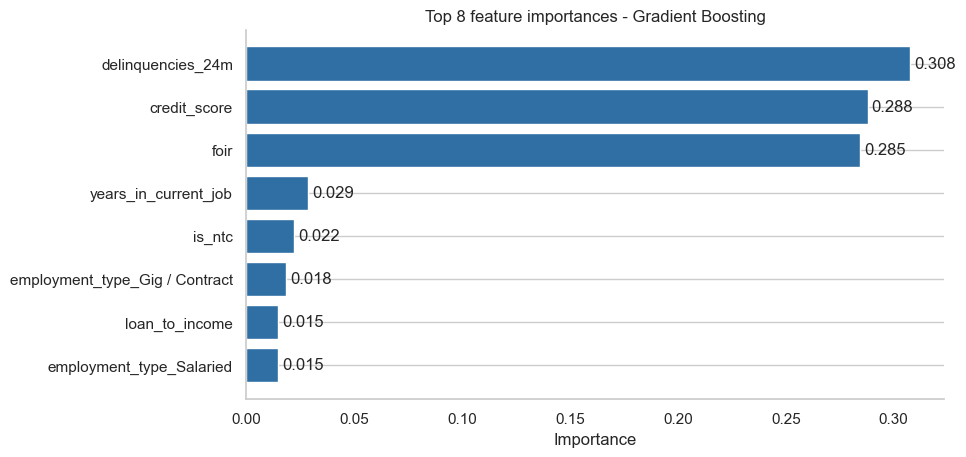

In [32]:
names = chosen_pipe.named_steps["preprocessor"].get_feature_names_out()
imp = pd.DataFrame({"feature": [n.split("__", 1)[1] for n in names],
                    "importance": chosen_pipe.named_steps["classifier"].feature_importances_})
top8 = imp.nlargest(8, "importance")
print(top8.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4.8))
t = top8.iloc[::-1]
bars = ax.barh(t["feature"], t["importance"], color=BLUE)
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set_title(f"Top 8 feature importances - {chosen_name}")
ax.set_xlabel("Importance")
plt.show()

### 5.9 Findings
| Model | Mean ROC-AUC | Accuracy | Precision (Declined) | Recall (Declined) |
|---|---:|---:|---:|---:|
| Gradient Boosting | 0.8889 | 0.7999 | 0.8117 | 0.7488 |
| Random Forest | 0.8786 | 0.7891 | 0.7796 | 0.7696 |
| Logistic Regression | 0.8679 | 0.7751 | 0.7803 | 0.7271 |
| Decision Tree | 0.7165 | 0.7176 | 0.7012 | 0.6974 |

I chose **Gradient Boosting** because it has the highest cross-validation ROC-AUC (0.889, and Logistic Regression has 0.868). The Decision Tree is the weakest (0.716). On the test set, Gradient Boosting has ROC-AUC 0.8854, accuracy 80.29%, precision 81.48% and recall 75.20% for Declined. Logistic Regression has test ROC-AUC 0.8674.

**Is the gain worth the loss in explainability?** The gain is small (about 0.018 in ROC-AUC) and Logistic Regression is easier to explain to a customer. But in step 5.10 this small gain gives 349 more automated applications every month, so I think it is worth it. The bank can still explain the decisions using the feature importances.

**Do the feature importances agree with 5.2 and 5.3?** Yes. The top 3 features are delinquencies_24m (0.308), credit_score (0.288) and foir (0.285), and together they are about 88% of the total importance. This matches the credit score rule, the FOIR trend and the biggest logistic regression coefficients.

## 5.10 Design the two-lane pre-screener
Here I use the probability of approval from the model. If it is below the low threshold, the application goes to the **auto-decline lane**. If it is above the high threshold, it goes to the **fast-track lane** (approved with a light check). The rest go to the **analyst**. The limits are: not more than 5% of the auto-decline lane should be applications that the team approved, and not more than 5% of the fast-track lane should be applications that the team declined. I searched all the threshold pairs (in steps of 0.01) and picked the pair that takes the most applications out of the manual queue and follows both limits. I did this for Gradient Boosting and for Logistic Regression.

In [33]:
def lane_stats(y_true, p_approve, low, high):
    y_true = np.asarray(y_true)
    dec = p_approve < low                      # auto-decline lane
    ft = p_approve >= high                     # fast-track lane
    n_dec, n_ft = int(dec.sum()), int(ft.sum())
    return {"Low threshold": low, "High threshold": high,
            "Auto-decline": n_dec, "Analyst review": len(y_true) - n_dec - n_ft, "Fast-track": n_ft,
            "Automated": n_dec + n_ft,
            "Auto-decline error rate": (y_true[dec] == 0).mean() if n_dec else 0.0,   # approved by credit team
            "Fast-track error rate": (y_true[ft] == 1).mean() if n_ft else 0.0}       # declined by credit team

def search_thresholds(y_true, p_approve, limit=0.05):
    grid = np.round(np.arange(0.01, 1.00, 0.01), 2)
    best = None
    for low in grid:
        for high in grid[grid > low]:
            r = lane_stats(y_true, p_approve, low, high)
            if r["Auto-decline error rate"] > limit or r["Fast-track error rate"] > limit:
                continue
            if best is None or r["Automated"] > best["Automated"]:
                best = r
    return best

p_chosen = chosen_pipe.predict_proba(X_test)[:, 0]          # probability of APPROVAL
p_logreg = baseline_pipeline.predict_proba(X_test)[:, 0]

res = pd.DataFrame([{"Model": chosen_name, **search_thresholds(y_test, p_chosen)},
                    {"Model": "Logistic Regression", **search_thresholds(y_test, p_logreg)}])
res.round(4)

,Model,Low threshold,High threshold,Auto-decline,Analyst review,Fast-track,Automated,Auto-decline error rate,Fast-track error rate
0,Gradient Boosting,0.17,0.89,587,1354,459,1046,0.0494,0.0458
1,Logistic Regression,0.10,0.89,365,1633,402,767,0.0466,0.0473


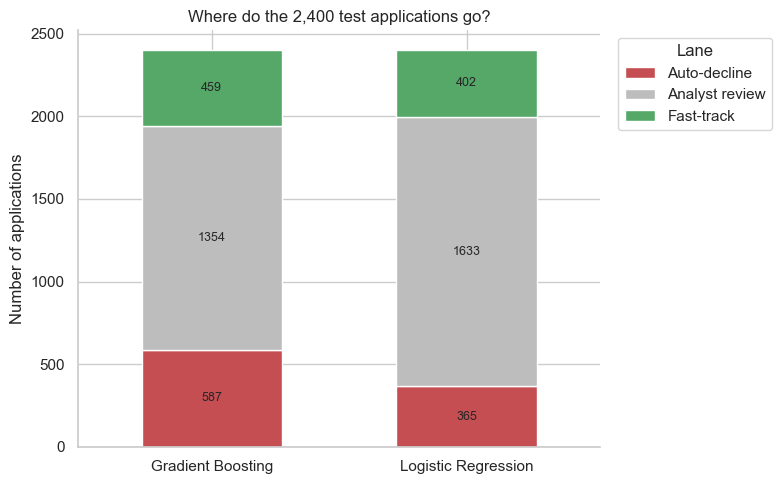

In [34]:
lanes = res.set_index("Model")[["Auto-decline", "Analyst review", "Fast-track"]]
fig, ax = plt.subplots(figsize=(8, 5))
lanes.plot(kind="bar", stacked=True, ax=ax, color=[RED, GREY, GREEN], edgecolor="white", width=0.55)
for c in ax.containers:
    ax.bar_label(c, label_type="center", fontsize=9)
ax.set_title("Where do the 2,400 test applications go?")
ax.set_xlabel("")
ax.set_ylabel("Number of applications")
ax.legend(title="Lane", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [35]:
monthly = res[["Model", "Auto-decline", "Analyst review", "Fast-track", "Automated"]].copy()
for lane in ["Auto-decline", "Fast-track", "Automated"]:
    monthly[f"{lane} / month"] = (monthly[lane] / len(y_test) * MONTHLY_APPS).round().astype(int)
monthly["Analyst hours saved / month"] = (monthly["Automated / month"] * MIN_PER_REVIEW / 60).round(1)
monthly["Share automated (%)"] = (monthly["Automated"] / len(y_test) * 100).round(1)
display(monthly.drop(columns=["Auto-decline", "Analyst review", "Fast-track", "Automated"]))

gb, lr = monthly.iloc[0], monthly.iloc[1]
print(f"{chosen_name} vs Logistic Regression: "
      f"+{gb['Automated / month'] - lr['Automated / month']} applications and "
      f"+{gb['Analyst hours saved / month'] - lr['Analyst hours saved / month']:.1f} analyst hours per month")

,Model,Auto-decline / month,Fast-track / month,Automated / month,Analyst hours saved / month,Share automated (%)
0,Gradient Boosting,734,574,1308,545.0,43.6
1,Logistic Regression,456,503,959,399.6,32.0


Gradient Boosting vs Logistic Regression: +349 applications and +145.4 analyst hours per month


In [36]:
# Extra check: the thresholds above were searched on the test set.
# Here I choose the thresholds on a validation set (taken from the training data)
# and then only check on the test set if the 5% limits still hold.
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.20, stratify=y_train, random_state=42)

check = []
for name, base in [(chosen_name, model_pipes[chosen_name]), ("Logistic Regression", model_pipes["Logistic Regression"])]:
    m = clone(base).fit(X_fit, y_fit)
    best_val = search_thresholds(y_val, m.predict_proba(X_val)[:, 0])
    on_test = lane_stats(y_test, m.predict_proba(X_test)[:, 0], best_val["Low threshold"], best_val["High threshold"])
    check.append({"Model": name, "Low": best_val["Low threshold"], "High": best_val["High threshold"],
                  "Automated % (validation)": best_val["Automated"] / len(y_val) * 100,
                  "Automated % (test)": on_test["Automated"] / len(y_test) * 100,
                  "Auto-decline error % (test)": on_test["Auto-decline error rate"] * 100,
                  "Fast-track error % (test)": on_test["Fast-track error rate"] * 100})
pd.DataFrame(check).round(2)

,Model,Low,High,Automated % (validation),Automated % (test),Auto-decline error % (test),Fast-track error % (test)
0,Gradient Boosting,0.17,0.88,43.70,44.42,4.51,5.10
1,Logistic Regression,0.12,0.92,29.38,30.08,5.29,3.27


### 5.10 Findings
| | **Gradient Boosting** | **Logistic Regression** |
|---|---:|---:|
| Thresholds (low / high) | 0.17 / 0.89 | 0.10 / 0.89 |
| Auto-decline lane | 587 (24.5%) | 365 (15.2%) |
| Analyst review | 1354 (56.4%) | 1633 (68.0%) |
| Fast-track lane | 459 (19.1%) | 402 (16.8%) |
| Auto-decline error rate | 4.94% | 4.66% |
| Fast-track error rate | 4.58% | 4.73% |
| Applications automated per month | 1,308 | 959 |
| Analyst hours saved per month | 545.0 | 399.6 |

Both models follow the 5% limit in both lanes. But Gradient Boosting takes 43.6% of the applications out of the manual queue and Logistic Regression takes only 32.0%. This means **349 more applications and about 145 more analyst hours per month** with Gradient Boosting.

**One point to note:** I searched the thresholds on the test set, so the error rates can look a little better than they will be on new data. So I did one more check: I chose the thresholds on a validation set (taken from the training data) and then applied them on the test set. The errors (auto-decline / fast-track) were 4.51% / 5.10% for Gradient Boosting and 5.29% / 3.27% for Logistic Regression. Gradient Boosting still automates more (44% vs 30%), but one of the errors goes a little above 5%, so the bank should keep some safety margin.

## Credit Policy Recommendation

- **Recommended model and thresholds:** Use **Gradient Boosting** with an auto-decline threshold of **0.17** and a fast-track threshold of **0.89** on the probability of approval.

- **Share of applications in each lane:** Auto-decline handles **24.5%**, fast-track handles **19.1%** and analyst review handles **56.4%** of the applications.

- **Monthly impact:** With 3,000 applications a month, about **1,308 applications** are taken out of manual review and about **545 analyst hours** are saved.

- **Comparison with Logistic Regression:** Logistic Regression automates 959 applications and saves 400 hours. So Gradient Boosting gives **349 more applications and 145 more analyst hours** every month.

- **Main risk of going live:** The model only learns the old decisions of the analysts, not the repayment results. The errors are also close to the 5% limit (4.9% and 4.6%). When I chose the thresholds on validation data, the errors became 4.5% and 5.1%.

- **Applicants who should always stay with a human:** The high-income segment (highest model error of 25% in step 5.12), new-to-credit applicants, and applications with missing or wrong information.

- **Fairness position and monitoring:** Gender is not used in the model. The auto-decline rate is 15.6% for women and 15.0% for men. But income and employment type can act as a substitute for gender, so the bank should check lane shares and error rates by gender and employment type every month.

- **What to test before full rollout:** Run the model in shadow mode for 1-2 months, where the model gives its decision but the analysts still take the final decision. Also keep an internal limit of about 4% for each lane, so the 5% limit is safe on new applications.

## 5.12 Stretch (optional): Where does the model struggle?
I used K-Means to group the applicants using scaled `monthly_income`, `credit_score`, `foir`, `years_in_current_job` and `age`. The scaler and K-Means are fitted on the training data only (blank credit scores are filled with the median). I used an elbow plot to choose the number of segments. For each segment I checked the size, the approval rate and the error rate of the chosen model on the test set. I did not use the cluster labels as a feature in the model.

  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.

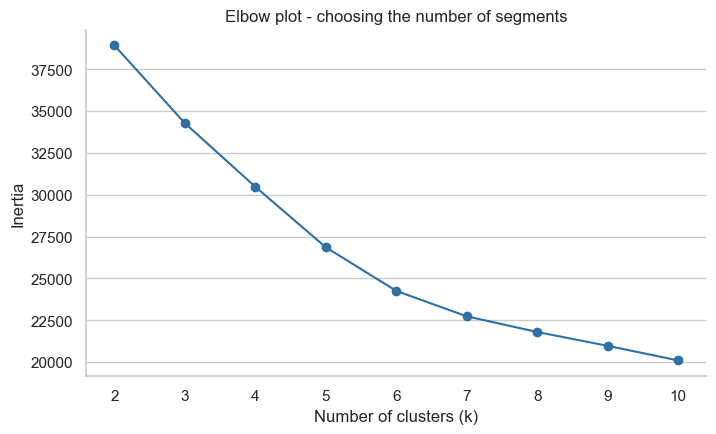

In [37]:
cluster_features = ["monthly_income", "credit_score", "foir", "years_in_current_job", "age"]
seg_train = df_clean.loc[X_train.index, cluster_features]
seg_test = df_clean.loc[X_test.index, cluster_features]

seg_prep = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
seg_train_s = seg_prep.fit_transform(seg_train)
seg_test_s = seg_prep.transform(seg_test)

ks = range(2, 11)
inertia = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(seg_train_s).inertia_ for k in ks]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(list(ks), inertia, marker="o", color=BLUE)
ax.set_xticks(list(ks))
ax.set_title("Elbow plot - choosing the number of segments")
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Inertia")
plt.show()

In [38]:
K = 4
km = KMeans(n_clusters=K, random_state=42, n_init=10).fit(seg_train_s)       # fitted on training applicants only
seg = seg_test.copy()
seg["cluster"] = km.predict(seg_test_s)
seg["actual_declined"] = y_test.to_numpy()
seg["model_error"] = (chosen_pipe.predict(X_test) != y_test.to_numpy()).astype(int)   # chosen model, default 0.5 cut-off

summary = seg.groupby("cluster").agg(
    size=("actual_declined", "size"),
    approval_rate=("actual_declined", lambda s: (1 - s.mean()) * 100),
    model_error_rate=("model_error", lambda s: s.mean() * 100),
    median_income=("monthly_income", "median"),
    median_score=("credit_score", "median"),
    median_foir=("foir", "median"),
    median_job_years=("years_in_current_job", "median"),
    median_age=("age", "median")).round(2)
summary

,size,approval_rate,model_error_rate,median_income,median_score,median_foir,median_job_years,median_age
cluster,,,,,,,,
0,555,69.37,18.92,52000.0,743.0,0.31,6.6,39.0
1,1161,53.49,20.76,43500.0,713.0,0.28,2.0,30.0
2,291,61.17,24.74,115000.0,729.0,0.30,3.2,36.0
3,393,22.14,13.99,47000.0,732.0,0.64,2.6,33.0


,segment,size,approval_rate,model_error_rate,median_income,median_score,median_foir,median_job_years,median_age
cluster,,,,,,,,,
0,"Established, long-tenure",555,69.37,18.92,52000.0,743.0,0.31,6.6,39.0
1,"Younger, short-tenure, lower income",1161,53.49,20.76,43500.0,713.0,0.28,2.0,30.0
2,High-income applicants,291,61.17,24.74,115000.0,729.0,0.30,3.2,36.0
3,High-FOIR / stretched borrowers,393,22.14,13.99,47000.0,732.0,0.64,2.6,33.0


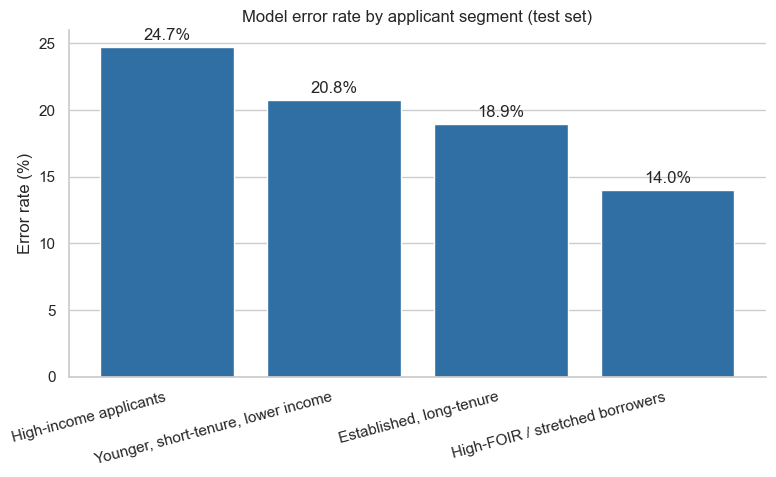

In [39]:
# Giving a business name to each segment based on its profile
names = {}
remaining = set(summary.index)
def take(label, idx):
    names[idx] = label
    remaining.discard(idx)

take("High-FOIR / stretched borrowers", summary.loc[list(remaining), "median_foir"].idxmax())
take("High-income applicants",          summary.loc[list(remaining), "median_income"].idxmax())
take("Established, long-tenure",        summary.loc[list(remaining), "median_job_years"].idxmax())
for r in remaining:
    names[r] = "Younger, short-tenure, lower income"

summary["segment"] = summary.index.map(names)
summary = summary[["segment", "size", "approval_rate", "model_error_rate", "median_income", "median_score", "median_foir", "median_job_years", "median_age"]]
display(summary)

fig, ax = plt.subplots(figsize=(9, 4.5))
order = summary.sort_values("model_error_rate", ascending=False)
bars = ax.bar(order["segment"], order["model_error_rate"], color=BLUE)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_title("Model error rate by applicant segment (test set)")
ax.set_ylabel("Error rate (%)")
plt.xticks(rotation=15, ha="right")
plt.show()

### 5.12 Findings
In the elbow plot there is no sharp elbow, the inertia goes down slowly. So I chose **k = 4**, because each segment is big enough and easy to understand.

| Segment | Test applicants | Approval rate | Model error rate |
|---|---:|---:|---:|
| High-income applicants | 291 | 61.2% | 24.7% |
| Younger, short-tenure, lower income | 1161 | 53.5% | 20.8% |
| Established, long-tenure | 555 | 69.4% | 18.9% |
| High-FOIR / stretched borrowers | 393 | 22.1% | 14.0% |

### Segmentation summary

**Key findings:**
- The high-income segment has the highest model error rate (24.7%).
- The high-FOIR segment has the lowest approval rate (22.1%) and the lowest error rate (14.0%).
- The biggest segment (younger, short-tenure, lower income, 1161 test applicants) also has a high error rate (20.8%).

**Which segment should always stay with a human analyst?** The high-income segment. The model is wrong for about 1 out of 4 applications in this group, there are fewer examples of them (291 in the test set), and their loan amounts are probably bigger, so a wrong automatic decision can cost more. The high-FOIR segment is easy for the model, so it is a good source of safe auto-declines.

**Limitations:** The error rate is calculated at the default 0.5 cut-off on one test set, so it may change on new data. The segments are only used to understand the applicants and the cluster labels are not used in the model.